In [8]:
import spacy
import matplotlib.pyplot as plt
from collections import Counter

In [13]:
text = """
Google announced a new Artificial Intelligence research project in Bengaluru.
Sundar Pichai said that Google will invest more money in AI research in India.
Microsoft is developing new AI tools with researchers from Hyderabad.
Satya Nadella visited Microsoft offices in Chennai to discuss AI innovation.
OpenAI is working with developers in California to build advanced AI systems.
Sam Altman said that artificial intelligence will transform education and healthcare.
The World Health Organization is studying the use of AI in healthcare.
WHO researchers in Geneva are developing guidelines for responsible AI.
IBM announced a new AI training program for students in Mumbai.
Arvind Krishna said that IBM will support universities in developing AI skills.
"""

doc = nlp(text)

In [14]:
# 2. Display POS tags
print("POS TAGGING:")
for token in doc:
    if not token.is_space:
        print(token.text, ":", token.pos_)

# 3. Extract nouns
nouns = [t.text for t in doc if t.pos_ == "NOUN"]
print("\nNOUNS:", nouns)

# 4. Extract verbs
verbs = [t.text for t in doc if t.pos_ == "VERB"]
print("\nVERBS:", verbs)

# 5 & 6. Named Entity Recognition
print("\nNAMED ENTITIES:")
for ent in doc.ents:
    print(ent.text, ":", ent.label_)

# 7. Count PERSON, ORG, GPE
entities = [e.label_ for e in doc.ents
            if e.label_ in ["PERSON", "ORG", "GPE"]]
counts = Counter(entities)

# 8. Display frequencies
print("\nENTITY FREQUENCIES:")
for label in ["PERSON", "ORG", "GPE"]:
    print(label, ":", counts[label])

POS TAGGING:
Google : PROPN
announced : VERB
a : DET
new : ADJ
Artificial : PROPN
Intelligence : PROPN
research : NOUN
project : NOUN
in : ADP
Bengaluru : PROPN
. : PUNCT
Sundar : PROPN
Pichai : PROPN
said : VERB
that : SCONJ
Google : PROPN
will : AUX
invest : VERB
more : ADJ
money : NOUN
in : ADP
AI : PROPN
research : NOUN
in : ADP
India : PROPN
. : PUNCT
Microsoft : PROPN
is : AUX
developing : VERB
new : ADJ
AI : PROPN
tools : NOUN
with : ADP
researchers : NOUN
from : ADP
Hyderabad : PROPN
. : PUNCT
Satya : PROPN
Nadella : PROPN
visited : VERB
Microsoft : PROPN
offices : NOUN
in : ADP
Chennai : PROPN
to : PART
discuss : VERB
AI : PROPN
innovation : NOUN
. : PUNCT
OpenAI : PROPN
is : AUX
working : VERB
with : ADP
developers : NOUN
in : ADP
California : PROPN
to : PART
build : VERB
advanced : ADJ
AI : PROPN
systems : NOUN
. : PUNCT
Sam : PROPN
Altman : PROPN
said : VERB
that : SCONJ
artificial : ADJ
intelligence : NOUN
will : AUX
transform : VERB
education : NOUN
and : CCONJ
healthcare

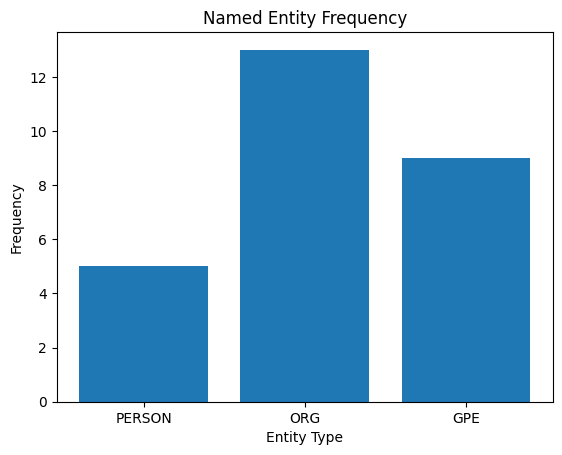

In [15]:
# 9. Bar plot
labels = ["PERSON", "ORG", "GPE"]
values = [counts[x] for x in labels]

plt.bar(labels, values)
plt.title("Named Entity Frequency")
plt.xlabel("Entity Type")
plt.ylabel("Frequency")
plt.show()

In [16]:

# 10. Analysis
orgs = [e.text for e in doc.ents if e.label_ == "ORG"]
people = [e.text for e in doc.ents if e.label_ == "PERSON"]
locations = [e.text for e in doc.ents if e.label_ == "GPE"]

print("\nANALYSIS:")
print("Organization mentions:", Counter(orgs))
print("Person mentions:", Counter(people))
print("Location mentions:", Counter(locations))

if orgs:
    print("Most frequent organization:", Counter(orgs).most_common(1)[0])
if people:
    print("People identified:", set(people))
if locations:
    print("Most frequent location:", Counter(locations).most_common(1)[0])

print("Main focus:", max(counts, key=counts.get) if counts else "None")


ANALYSIS:
Organization mentions: Counter({'AI': 3, 'Google': 2, 'Microsoft': 2, 'IBM': 2, 'Artificial Intelligence': 1, 'Hyderabad': 1, 'Chennai': 1, 'The World Health Organization': 1})
Person mentions: Counter({'Sundar Pichai': 1, 'Satya Nadella': 1, 'OpenAI': 1, 'Sam Altman': 1, 'Arvind Krishna': 1})
Location mentions: Counter({'AI': 4, 'Bengaluru': 1, 'India': 1, 'California': 1, 'Geneva': 1, 'Mumbai': 1})
Most frequent organization: ('AI', 3)
People identified: {'Arvind Krishna', 'Sundar Pichai', 'OpenAI', 'Sam Altman', 'Satya Nadella'}
Most frequent location: ('AI', 4)
Main focus: ORG
